# Feature redundancy
Area and Convex_Area show very similar distributions, as observed from their boxplots and descriptive statistics. The scatter plot also shows an extremely strong linear relationship between the two features, which is supported by their correlation coefficient of approximately 1.00. Both features exhibit similar class patterns. Therefore, Area and Convex_Area contain highly similar information and may be redundant. To reduce potential redundancy in Logistic Regression, we will evaluate a reduced feature set by removing one of these features and compare its performance with the model using both features.

In [45]:
features_set1 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set2 = ['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
features_set3 = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Extent']

In [46]:
import pandas as pd

train_set1 = pd.read_csv("train_set1.csv")

X_train_set1 = train_set1.drop(columns=["Target"])
y_train_set1 = train_set1["Target"]

train_set2 = pd.read_csv("train_set2.csv")

X_train_set2 = train_set2.drop(columns=["Target"])
y_train_set2 = train_set2["Target"]

train_set3 = pd.read_csv("train_set3.csv")

X_train_set3 = train_set3.drop(columns=["Target"])
y_train_set3 = train_set3["Target"]

# Train the model without 'Convex_Area' (set 3)

# Feature scaling

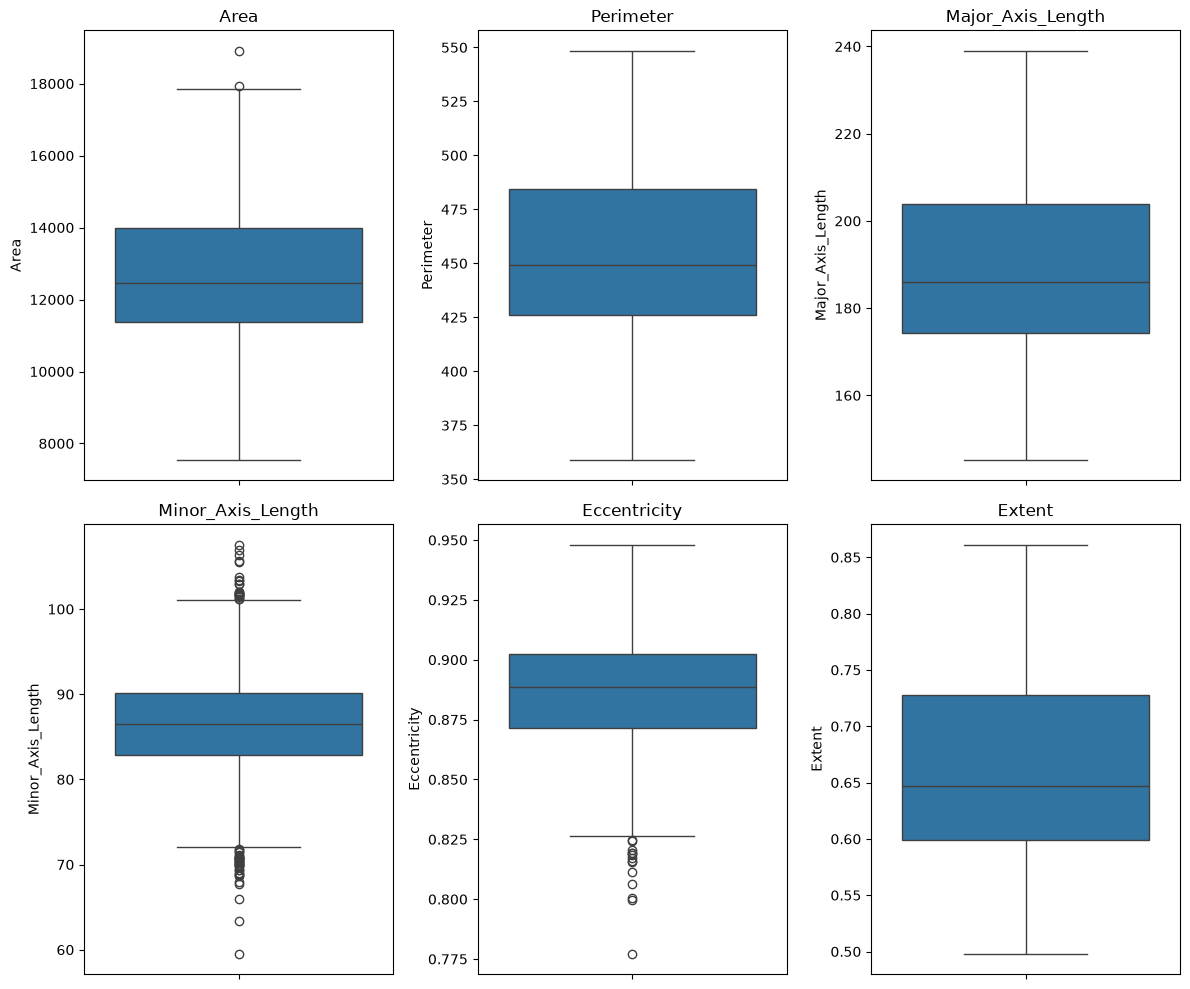

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(X_train_set3.columns):
    sns.boxplot(y=X_train_set3[col], ax=axes[i])
    axes[i].set_title(col)


plt.tight_layout()
plt.show()

Features with outliers can scale using non-sensitive scaling method such as Robust scaling and others can scale using Standard Scaler

In [48]:
features_outliers_set3 = ['Eccentricity', 'Minor_Axis_Length', 'Area']
features_non_outliers_set3  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set3[features_non_outliers_set3])

In [50]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set3[features_outliers_set3])

In [51]:
# Combine the scaled features

X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set3,
        index=X_train_set3.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set3,
        index=X_train_set3.index
    )
], axis=1)

In [52]:
# Basic KNN implementation

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np

# Create the model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    knn_model,
    X_train_scaled,
    y_train_set3,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [53]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93888433 0.9392945  0.93970468 0.94095941 0.93726937]
Validation accuracy: [0.92295082 0.9295082  0.92786885 0.91789819 0.93267652]
Mean training accuracy: 0.9392224586724949
Mean validation accuracy: 0.9261805162992275
Validation accuracy std: 0.00519903438142641
Mean F1: 0.924631675020809
Mean Precision: 0.9245954930415475
Mean Recall: 0.9247554969484622


## Hyperparameter tuning

In [54]:
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

# Preprocessing
preprocessor_knn = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set3),
    ('robust', RobustScaler(), features_outliers_set3)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# KNN pipeline
pipeline_knn = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('model', KNeighborsClassifier())
])

# Hyperparameter grid
param_grid_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21]
}

# Grid Search
grid_search_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_knn.fit(X_train_set3, y_train_set3)

print("Best Parameters:", grid_search_knn.best_params_)
print("Best CV Accuracy:", grid_search_knn.best_score_)

Best Parameters: {'model__n_neighbors': 15}
Best CV Accuracy: 0.9281498829039811


In [55]:
# Obtain best model

best_knn_model = grid_search_knn.best_estimator_

In [56]:
results = pd.DataFrame(grid_search_knn.cv_results_)
best_results = results.loc[grid_search_knn.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_knn.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__n_neighbors': 15}
Mean Train Accuracy:      0.9347
Mean CV Accuracy:         0.9281
Mean CV Precision:        0.9272
Mean CV Recall:           0.9262
Mean CV F1-Score:         0.9265
Train-CV Accuracy Gap:    0.0066
No strong overfitting signal based on this accuracy gap.


### Extract the results

In [57]:
results_knn = grid_search_knn.cv_results_

for k, score in zip(
    results_knn['param_model__n_neighbors'],
    results_knn['mean_test_accuracy']
):
    print(f"K = {k}, CV Accuracy = {score:.4f}")

K = 3, CV Accuracy = 0.9173
K = 5, CV Accuracy = 0.9226
K = 7, CV Accuracy = 0.9249
K = 9, CV Accuracy = 0.9275
K = 11, CV Accuracy = 0.9272
K = 15, CV Accuracy = 0.9281
K = 21, CV Accuracy = 0.9265


### Plot the chart

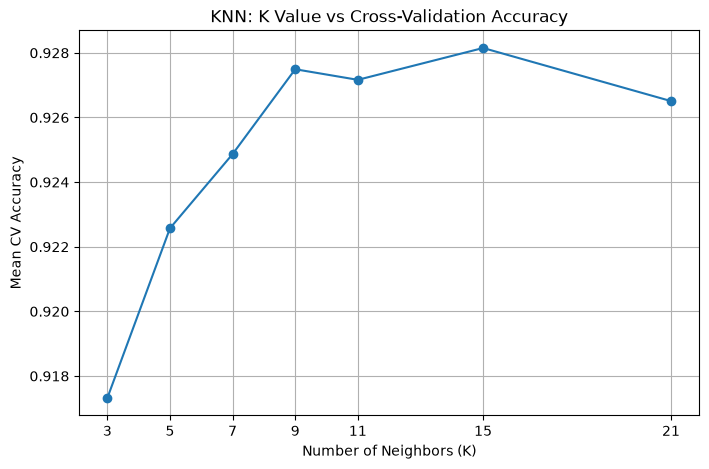

In [58]:
import matplotlib.pyplot as plt

k_values = results_knn['param_model__n_neighbors'].data
cv_scores = results_knn['mean_test_accuracy']

plt.figure(figsize=(8, 5))

plt.plot(k_values, cv_scores, marker='o')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("KNN: K Value vs Cross-Validation Accuracy")

plt.xticks(k_values)
plt.grid(True)

plt.show()

# Train the model with all features (set 1)

# Feature scaling

Features with outliers can scale using non-sensitive scaling method such as Robust scaling and others can scale using Standard Scaler

In [59]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area', 'Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [60]:
scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set1[features_non_outliers_set1])

In [61]:
scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set1[features_outliers_set1])

In [62]:
# Combine the scaled features
X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set1,
        index=X_train_set1.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set1,
        index=X_train_set1.index
    )
], axis=1)

In [63]:
# Create the model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    knn_model,
    X_train_scaled,
    y_train_set1,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [64]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93765381 0.93847416 0.93806399 0.94300943 0.93603936]
Validation accuracy: [0.92622951 0.93278689 0.9295082  0.91625616 0.93596059]
Mean training accuracy: 0.9386481502222732
Mean validation accuracy: 0.9281482677864815
Validation accuracy std: 0.006774990729445977
Mean F1: 0.9266841232805847
Mean Precision: 0.9263864697665554
Mean Recall: 0.9270543475231747


## Hyperparameter tuning

In [65]:
scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Preprocessing
preprocessor_knn = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set1),
    ('robust', RobustScaler(), features_outliers_set1)
])

# KNN pipeline
pipeline_knn = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('model', KNeighborsClassifier())
])

# Hyperparameter grid
param_grid_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21]
}

# Grid Search
grid_search_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_knn.fit(X_train_set1, y_train_set1)

print("Best Parameters:", grid_search_knn.best_params_)
print("Best CV Accuracy:", grid_search_knn.best_score_)

Best Parameters: {'model__n_neighbors': 15}
Best CV Accuracy: 0.9294618966863173


In [66]:
# Obtain best model

best_knn_model = grid_search_knn.best_estimator_

In [67]:
results = pd.DataFrame(grid_search_knn.cv_results_)
best_results = results.loc[grid_search_knn.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_knn.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__n_neighbors': 15}
Mean Train Accuracy:      0.9345
Mean CV Accuracy:         0.9295
Mean CV Precision:        0.9286
Mean CV Recall:           0.9274
Mean CV F1-Score:         0.9279
Train-CV Accuracy Gap:    0.0050
No strong overfitting signal based on this accuracy gap.


# Train the model without 'Area' (Set 2)

# Feature scaling

Features with outliers can scale using non-sensitive scaling method such as Robust scaling and others can scale using Standard Scaler

In [68]:
features_outliers_set2 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area']
features_non_outliers_set2  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [69]:
scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set2[features_non_outliers_set2])

In [70]:
scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set2[features_outliers_set2])

In [71]:
# Combine the scaled features

X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set2,
        index=X_train_set2.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set2,
        index=X_train_set2.index
    )
], axis=1)

In [72]:
# Create the model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    knn_model,
    X_train_scaled,
    y_train_set2,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [73]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93888433 0.93847416 0.93847416 0.94259943 0.93644936]
Validation accuracy: [0.92295082 0.93114754 0.9295082  0.91954023 0.93103448]
Mean training accuracy: 0.9389762880401568
Mean validation accuracy: 0.9268362540041455
Validation accuracy std: 0.004726101265794017
Mean F1: 0.9253022233573326
Mean Precision: 0.9252571150560822
Mean Recall: 0.9254266452843669


## Hyperparameter tuning

In [74]:
# Preprocessing
preprocessor_knn = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set2),
    ('robust', RobustScaler(), features_outliers_set2)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# KNN pipeline
pipeline_knn = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('model', KNeighborsClassifier())
])

# Hyperparameter grid
param_grid_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21]
}

# Grid Search
grid_search_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_knn.fit(X_train_set2, y_train_set2)

print("Best Parameters:", grid_search_knn.best_params_)
print("Best CV Accuracy:", grid_search_knn.best_score_)

Best Parameters: {'model__n_neighbors': 15}
Best CV Accuracy: 0.9281488061589813


In [75]:
# Obtain best model

best_knn_model = grid_search_knn.best_estimator_

In [76]:
results = pd.DataFrame(grid_search_knn.cv_results_)
best_results = results.loc[grid_search_knn.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_knn.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__n_neighbors': 15}
Mean Train Accuracy:      0.9343
Mean CV Accuracy:         0.9281
Mean CV Precision:        0.9272
Mean CV Recall:           0.9262
Mean CV F1-Score:         0.9265
Train-CV Accuracy Gap:    0.0062
No strong overfitting signal based on this accuracy gap.


In [77]:
results_knn = grid_search_knn.cv_results_

for k, score in zip(
    results_knn['param_model__n_neighbors'],
    results_knn['mean_test_accuracy']
):
    print(f"K = {k}, CV Accuracy = {score:.4f}")

K = 3, CV Accuracy = 0.9199
K = 5, CV Accuracy = 0.9249
K = 7, CV Accuracy = 0.9262
K = 9, CV Accuracy = 0.9265
K = 11, CV Accuracy = 0.9275
K = 15, CV Accuracy = 0.9281
K = 21, CV Accuracy = 0.9275


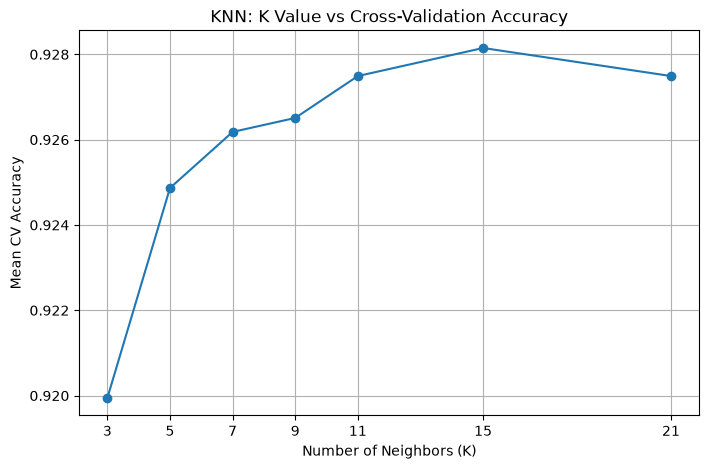

In [78]:
k_values = results_knn['param_model__n_neighbors'].data
cv_scores = results_knn['mean_test_accuracy']

plt.figure(figsize=(8, 5))

plt.plot(k_values, cv_scores, marker='o')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("KNN: K Value vs Cross-Validation Accuracy")

plt.xticks(k_values)
plt.grid(True)

plt.show()

# Evaluate models removing outliers

## Outlier distribution of training and testing set
(Model without redundant feature 'Area')

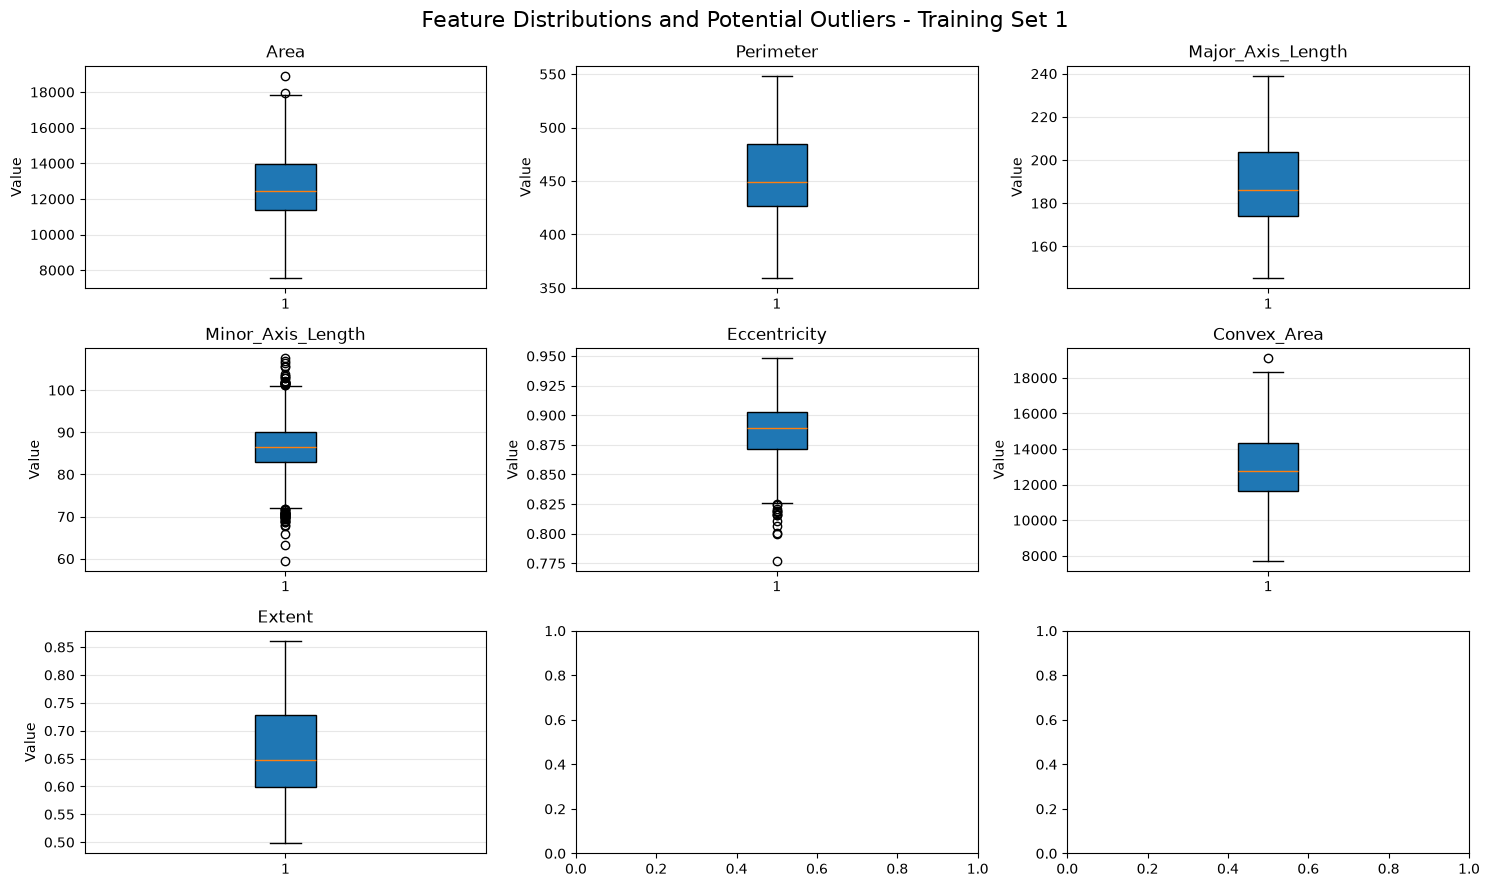

In [79]:
features_set1 = X_train_set1.columns

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set1):
    axes[i].boxplot(
        X_train_set1[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 1",
    fontsize=16
)

plt.tight_layout()
plt.show()

In training set, Minor_Axis_Length, Eccentricity and Convex area has outliers.

In [80]:
outlier_features = [
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area",
    "Area"
]

X_train_set1_clean = X_train_set1.copy()
y_train_set1_clean = y_train_set1.copy()

for feature in outlier_features:

    Q1 = X_train_set1_clean[feature].quantile(0.25)
    Q3 = X_train_set1_clean[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = (
        (X_train_set1_clean[feature] >= lower_bound) &
        (X_train_set1_clean[feature] <= upper_bound)
    )

    X_train_set1_clean = X_train_set1_clean[mask]
    y_train_set1_clean = y_train_set1_clean.loc[X_train_set1_clean.index]

    print(f"{feature}")
    print(f"Lower bound: {lower_bound:.4f}")
    print(f"Upper bound: {upper_bound:.4f}")
    print(f"Remaining rows: {len(X_train_set1_clean)}")
    print()

Minor_Axis_Length
Lower bound: 71.9833
Upper bound: 101.0960
Remaining rows: 2991

Eccentricity
Lower bound: 0.8261
Upper bound: 0.9477
Remaining rows: 2977

Convex_Area
Lower bound: 7690.0000
Upper bound: 18290.0000
Remaining rows: 2977

Area
Lower bound: 7575.0000
Upper bound: 17815.0000
Remaining rows: 2977



In [81]:
# Removed rows count
print("Original training rows:", len(X_train_set1))
print("Clean training rows:", len(X_train_set1_clean))
print("Rows removed:", len(X_train_set1) - len(X_train_set1_clean))

Original training rows: 3048
Clean training rows: 2977
Rows removed: 71


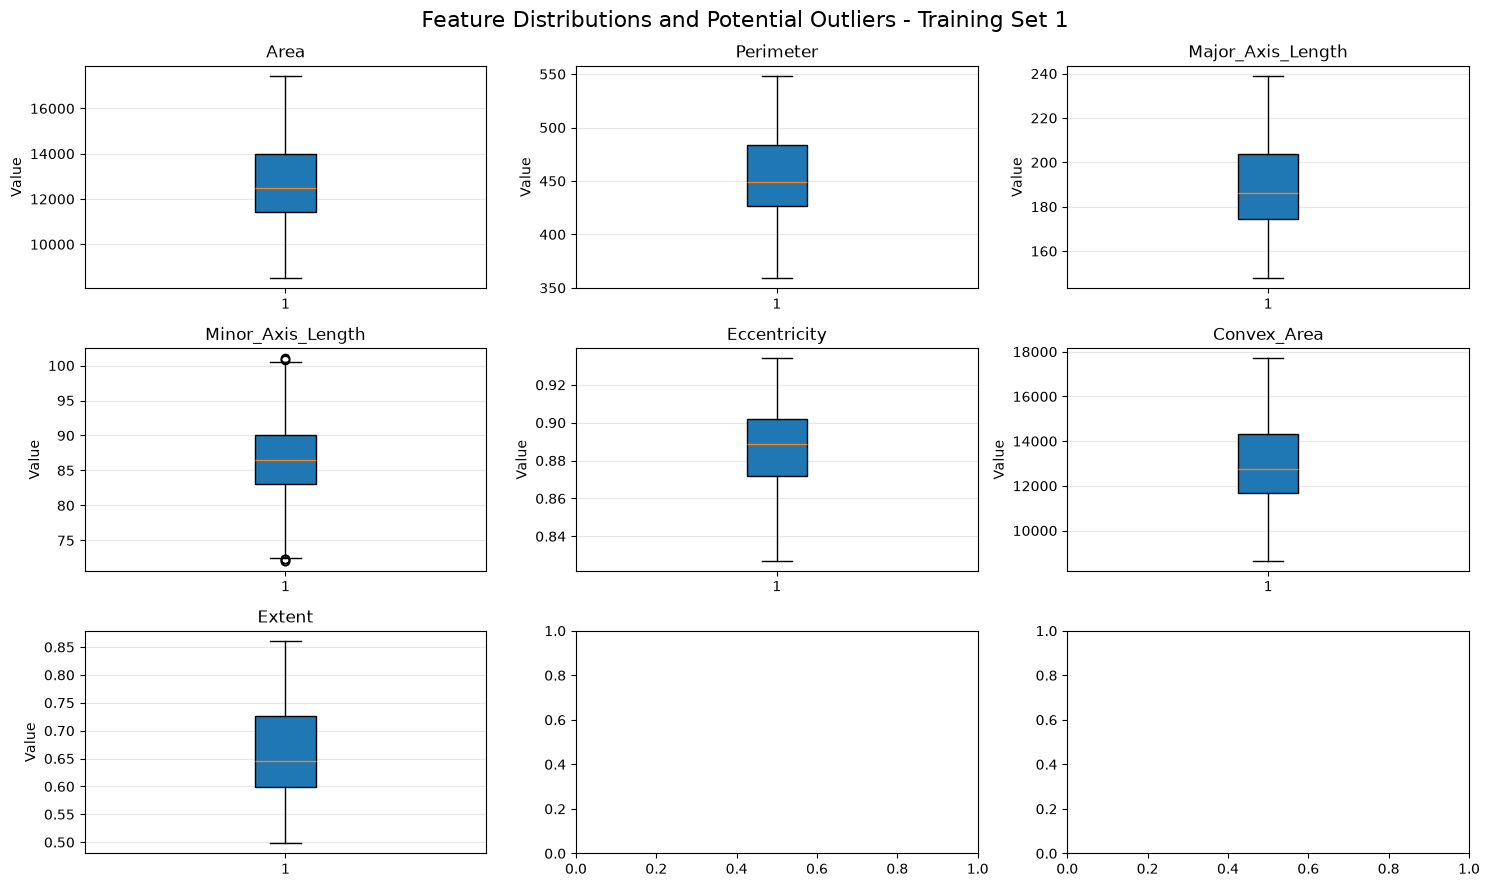

In [82]:
features_set1 = X_train_set1_clean.columns

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i, feature in enumerate(features_set1):
    axes[i].boxplot(
        X_train_set1_clean[feature],
        patch_artist=True
    )
    
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Feature Distributions and Potential Outliers - Training Set 1",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Train the model using cleaned training data

# Feature scaling

Features with outliers can scale using non-sensitive scaling method such as Robust scaling and others can scale using Standard Scaler

In [83]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [84]:
scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set1_clean[features_non_outliers_set1])

In [85]:
scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set1_clean[features_outliers_set1])

In [86]:
# Combine the scaled features
X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set1,
        index=X_train_set1_clean.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set1,
        index=X_train_set1_clean.index
    )
], axis=1)

In [87]:

# Create the model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    knn_model,
    X_train_scaled,
    y_train_set1_clean,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [88]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93742125 0.93910122 0.94080605 0.93828715 0.94080605]
Validation accuracy: [0.92114094 0.91610738 0.91932773 0.9210084  0.92941176]
Mean training accuracy: 0.9392843427766205
Mean validation accuracy: 0.9213992442614629
Validation accuracy std: 0.004398066142297313
Mean F1: 0.9197386202801011
Mean Precision: 0.9205851249743333
Mean Recall: 0.9193579344550742


## Hyperparameter tuning

In [89]:
# Preprocessing
preprocessor_knn = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set1),
    ('robust', RobustScaler(), features_outliers_set1)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# KNN pipeline
pipeline_knn = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('model', KNeighborsClassifier())
])

# Hyperparameter grid
param_grid_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21]
}

# Grid Search
grid_search_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Train
grid_search_knn.fit(X_train_set1_clean, y_train_set1_clean)

print("Best Parameters:", grid_search_knn.best_params_)
print("Best CV Accuracy:", grid_search_knn.best_score_)

Best Parameters: {'model__n_neighbors': 15}
Best CV Accuracy: 0.9277784670915347


In [90]:
# Obtain best model

best_knn_model = grid_search_knn.best_estimator_

In [91]:
results = pd.DataFrame(grid_search_knn.cv_results_)
best_results = results.loc[grid_search_knn.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_knn.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__n_neighbors': 15}
Mean Train Accuracy:      0.9329
Mean CV Accuracy:         0.9278
Mean CV Precision:        0.9269
Mean CV Recall:           0.9259
Mean CV F1-Score:         0.9263
Train-CV Accuracy Gap:    0.0051
No strong overfitting signal based on this accuracy gap.


# Check class imbalance

In [92]:
class_distribution = pd.DataFrame({
    "Count": y_train_set1.value_counts(),
    "Percentage": y_train_set1.value_counts(normalize=True) * 100
})

print(class_distribution)

          Count  Percentage
Target                     
Osmancik   1744   57.217848
Cammeo     1304   42.782152


### Balance the classes using SMOTE

In [93]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_set1_balanced, y_train_set1_balanced = smote.fit_resample(
    X_train_set1,
    y_train_set1
)

In [94]:
class_distribution_balanced = pd.DataFrame({
    "Count": y_train_set1_balanced.value_counts(),
    "Percentage": y_train_set1_balanced.value_counts(normalize=True) * 100
})

print(class_distribution_balanced)

          Count  Percentage
Target                     
Osmancik   1744        50.0
Cammeo     1744        50.0


### Train the final selected model

# Train the model without 'Area' (Set 2)

# Feature scaling

Features with outliers can scale using non-sensitive scaling method such as Robust scaling and others can scale using Standard Scaler

In [95]:
features_outliers_set1 = ['Eccentricity', 'Minor_Axis_Length', 'Convex_Area', 'Area']
features_non_outliers_set1  = ['Extent', 'Major_Axis_Length', 'Perimeter']

In [96]:
scaler = StandardScaler()

X_train_scaled_non_outliers = scaler.fit_transform(X_train_set1_balanced[features_non_outliers_set1])

In [97]:
scaler = RobustScaler()

X_train_scaled_outliers = scaler.fit_transform(X_train_set1_balanced[features_outliers_set1])

In [98]:
# Combine the scaled features
X_train_scaled = pd.concat([
    pd.DataFrame(
        X_train_scaled_non_outliers,
        columns=features_non_outliers_set1,
        index=X_train_set1_balanced.index
    ),
    pd.DataFrame(
        X_train_scaled_outliers,
        columns=features_outliers_set1,
        index=X_train_set1_balanced.index
    )
], axis=1)

In [99]:
# Create the model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate baseline model
scores = cross_validate(
    knn_model,
    X_train_scaled,
    y_train_set1_balanced,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro'
    },
    return_train_score=True
)

In [100]:
# Training accuracy for each fold
print("Training accuracy:", scores['train_accuracy'])

# Validation accuracy for each fold
print("Validation accuracy:", scores['test_accuracy'])

# Mean accuracy
print("Mean training accuracy:",
      scores['train_accuracy'].mean())

print("Mean validation accuracy:",
      scores['test_accuracy'].mean())

# Standard deviation
print("Validation accuracy std:",
      scores['test_accuracy'].std())

# Other evaluation metrics
print("Mean F1:", scores['test_f1_macro'].mean())
print("Mean Precision:", scores['test_precision_macro'].mean())
print("Mean Recall:", scores['test_recall_macro'].mean())

Training accuracy: [0.93870968 0.94121864 0.93476703 0.94733071 0.93658187]
Validation accuracy: [0.9226361  0.92120344 0.93409742 0.89526542 0.93256815]
Mean training accuracy: 0.9397215833278754
Mean validation accuracy: 0.9211541070408176
Validation accuracy std: 0.013930056963555116
Mean F1: 0.9211341895617162
Mean Precision: 0.921518923720145
Mean Recall: 0.9211490959391366


## Hyperparameter tuning

In [102]:
from imblearn.pipeline import Pipeline

# Preprocessing
preprocessor_knn = ColumnTransformer([
    ('standard', StandardScaler(), features_non_outliers_set1),
    ('robust', RobustScaler(), features_outliers_set1)
])

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# Scaling -> SMOTE -> KNN
pipeline_knn_smote = Pipeline([
    ('preprocessor', preprocessor_knn),
    ('smote', SMOTE(random_state=42)),
    ('model', KNeighborsClassifier())
])

# Hyperparameter grid
param_grid_knn_smote = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21]
}

# Grid Search with 5-fold CV
grid_search_knn_smote = GridSearchCV(
    estimator=pipeline_knn_smote,
    param_grid=param_grid_knn_smote,
    cv=5,
    scoring=scoring_metrics,
    refit='accuracy',
    n_jobs=-1,
    return_train_score=True
)

# Use the ORIGINAL training data, not a pre-balanced dataset
grid_search_knn_smote.fit(X_train_set1, y_train_set1)

print("Best Parameters:", grid_search_knn_smote.best_params_)
print("Best CV Accuracy:", grid_search_knn_smote.best_score_)

Best Parameters: {'model__n_neighbors': 21}
Best CV Accuracy: 0.9278187838165227


In [103]:
# Obtain best model

best_knn_model = grid_search_knn_smote.best_estimator_

In [104]:
results = pd.DataFrame(grid_search_knn_smote.cv_results_)
best_results = results.loc[grid_search_knn_smote.best_index_]

train_accuracy = best_results['mean_train_accuracy']
cv_accuracy = best_results['mean_test_accuracy']
accuracy_gap = train_accuracy - cv_accuracy

print("Best Parameters:", grid_search_knn_smote.best_params_)
print(f"Mean Train Accuracy:      {train_accuracy:.4f}")
print(f"Mean CV Accuracy:         {cv_accuracy:.4f}")
print(f"Mean CV Precision:        {best_results['mean_test_precision']:.4f}")
print(f"Mean CV Recall:           {best_results['mean_test_recall']:.4f}")
print(f"Mean CV F1-Score:         {best_results['mean_test_f1']:.4f}")
print(f"Train-CV Accuracy Gap:    {accuracy_gap:.4f}")

if accuracy_gap > 0.10:
    print("Possible overfitting: training accuracy is considerably higher.")
elif accuracy_gap > 0.05:
    print("Some overfitting may be present: inspect the model further.")
else:
    print("No strong overfitting signal based on this accuracy gap.")

Best Parameters: {'model__n_neighbors': 21}
Mean Train Accuracy:      0.9319
Mean CV Accuracy:         0.9278
Mean CV Precision:        0.9258
Mean CV Recall:           0.9278
Mean CV F1-Score:         0.9265
Train-CV Accuracy Gap:    0.0041
No strong overfitting signal based on this accuracy gap.


# Forward Feature Selection

In [108]:
# Configure cross-validation
cv_ffs = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

# Define scaling groups
features_non_outliers_set1 = [
    "Perimeter",
    "Major_Axis_Length",
    "Extent"
]

features_outliers_set1 = [
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area",
    "Area"
]

# Create pipeline for any feature subset
def build_knn_pipeline(selected_features):

    selected_features = list(selected_features)

    standard_features = [
        f for f in features_non_outliers_set1
        if f in selected_features
    ]

    robust_features = [
        f for f in features_outliers_set1
        if f in selected_features
    ]

    transformers = []

    if standard_features:
        transformers.append(
            ("standard", StandardScaler(), standard_features)
        )

    if robust_features:
        transformers.append(
            ("robust", RobustScaler(), robust_features)
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=15))
    ])


# Implement Forward Feature Selection
selected_features = []
remaining_features = X_train_set1.columns.tolist()
ffs_results = []

while remaining_features:

    candidate_results = []

    for feature in remaining_features:

        candidate_features = selected_features + [feature]

        pipeline = build_knn_pipeline(candidate_features)

        scores = cross_validate(
            pipeline,
            X_train_set1[candidate_features],
            y_train_set1,
            cv=cv_ffs,
            scoring=scoring_metrics,
            return_train_score=True,
            n_jobs=-1
        )

        candidate_results.append({
            "Feature": feature,
            "Train Accuracy":
                scores["train_accuracy"].mean(),
            "Mean CV Accuracy":
                scores["test_accuracy"].mean(),
            "CV Std":
                scores["test_accuracy"].std(),
            "Precision":
                scores["test_precision"].mean(),
            "Recall":
                scores["test_recall"].mean(),
            "F1-Score":
                scores["test_f1"].mean()
        })

    # Select feature with the highest mean CV accuracy
    candidate_results.sort(
        key=lambda x: x["Mean CV Accuracy"],
        reverse=True
    )

    best_candidate = candidate_results[0]

    selected_features.append(best_candidate["Feature"])
    remaining_features.remove(best_candidate["Feature"])

    ffs_results.append({
        "Step": len(selected_features),
        "Added Feature": best_candidate["Feature"],
        "Selected Features": selected_features.copy(),
        "Number of Features": len(selected_features),
        "Train Accuracy": best_candidate["Train Accuracy"],
        "Mean CV Accuracy": best_candidate["Mean CV Accuracy"],
        "CV Std": best_candidate["CV Std"],
        "Precision": best_candidate["Precision"],
        "Recall": best_candidate["Recall"],
        "F1-Score": best_candidate["F1-Score"]
    })


# Create results DataFrame
ffs_df = pd.DataFrame(ffs_results)

# Display results
display(
    ffs_df.style.format({
        "Train Accuracy": "{:.2%}",
        "Mean CV Accuracy": "{:.2%}",
        "CV Std": "{:.4f}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
)

# Identify the best feature subset
best_idx = ffs_df["Mean CV Accuracy"].idxmax()
best_row = ffs_df.loc[best_idx]

best_features_ffs = best_row["Selected Features"]

print("\nBest feature subset:", best_features_ffs)
print("Number of features:", len(best_features_ffs))
print(f"Train Accuracy: {best_row['Train Accuracy']:.4%}")
print(f"Mean CV Accuracy: {best_row['Mean CV Accuracy']:.4%}")
print(f"CV Standard Deviation: {best_row['CV Std']:.4f}")
print(f"Precision: {best_row['Precision']:.4%}")
print(f"Recall: {best_row['Recall']:.4%}")
print(f"F1-Score: {best_row['F1-Score']:.4%}")


,Step,Added Feature,Selected Features,Number of Features,Train Accuracy,Mean CV Accuracy,CV Std,Precision,Recall,F1-Score
0,1,Major_Axis_Length,['Major_Axis_Length'],1,93.32%,92.58%,0.0121,92.47%,92.39%,92.42%
1,2,Perimeter,"['Major_Axis_Length', 'Perimeter']",2,93.41%,93.08%,0.0072,92.99%,92.90%,92.93%
2,3,Convex_Area,"['Major_Axis_Length', 'Perimeter', 'Convex_Area']",3,93.42%,93.01%,0.0100,92.89%,92.85%,92.86%
3,4,Extent,"['Major_Axis_Length', 'Perimeter', 'Convex_Area', 'Extent']",4,93.32%,92.85%,0.0082,92.71%,92.70%,92.70%
4,5,Area,"['Major_Axis_Length', 'Perimeter', 'Convex_Area', 'Extent', 'Area']",5,93.29%,92.78%,0.0094,92.66%,92.61%,92.63%
5,6,Eccentricity,"['Major_Axis_Length', 'Perimeter', 'Convex_Area', 'Extent', 'Area', 'Eccentricity']",6,93.39%,92.78%,0.0081,92.64%,92.63%,92.63%
6,7,Minor_Axis_Length,"['Major_Axis_Length', 'Perimeter', 'Convex_Area', 'Extent', 'Area', 'Eccentricity', 'Minor_Axis_Length']",7,93.43%,92.95%,0.0100,92.86%,92.73%,92.79%



Best feature subset: ['Major_Axis_Length', 'Perimeter']
Number of features: 2
Train Accuracy: 93.4137%
Mean CV Accuracy: 93.0773%
CV Standard Deviation: 0.0072
Precision: 92.9866%
Recall: 92.8972%
F1-Score: 92.9258%


In [109]:

import joblib
from datetime import datetime

# 1. Get the best feature subset from FFS
selected_features = list(best_features_ffs)

print("Selected features:", selected_features)

# 2. Build a fresh pipeline using the selected features
final_knn_ffs = build_knn_pipeline(selected_features)

# 3. Train the final model using the complete training set
final_knn_ffs.fit(
    X_train_set1[selected_features],
    y_train_set1
)

# 4. Store the model and all required metadata
model_bundle = {
    "model": final_knn_ffs,
    "selected_features": selected_features,
    "model_name": "KNN - Set 1 FFS",
    "n_neighbors": 15,
    "cv_metrics": {
        "train_accuracy": float(best_row["Train Accuracy"]),
        "mean_cv_accuracy": float(best_row["Mean CV Accuracy"]),
        "cv_std": float(best_row["CV Std"]),
        "precision_macro": float(best_row["Precision"]),
        "recall_macro": float(best_row["Recall"]),
        "f1_macro": float(best_row["F1-Score"])
    },
    "saved_at": datetime.now().isoformat()
}

# 5. Save everything in one file
joblib.dump(
    model_bundle,
    "knn_set1_ffs.joblib"
)

print("\nModel saved successfully!")
print("File: knn_set1_ffs.joblib")
print("Number of features:", len(selected_features))
print(
    "Mean CV accuracy:",
    f"{best_row['Mean CV Accuracy']:.2%}"
)


Selected features: ['Major_Axis_Length', 'Perimeter']

Model saved successfully!
File: knn_set1_ffs.joblib
Number of features: 2
Mean CV accuracy: 93.08%


| Feature set | Train-Accuracy | CV-Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|--:|
| Set 3 | 93.47% | 92.81% | 92.72% | 92.62% | 92.65% | 
| Set 2 | 93.43% | 92.81% | 92.72% | 92.62% | 92.65% |
| Set 1 | 93.45% | 92.95% | 92.86% | 92.74% | 92.79% |
| Set 2 (SMOTE) | 93.19% | 92.78% | 92.58% | 92.78% | 92.65% |
| Set 2 (Remove outlier) | 93.29% | 92.78% | 92.69% | 92.59% |92.63% |
| Set 1 (FFS) | 93.41% | 93.08% | 92.99% | 92.90% | 92.93% |

## Conclusion: KNN Model Comparison

Based on the experimental results, **KNN with Set 1 and Forward Feature Selection (FFS)** is the preferred candidate among the evaluated configurations. It achieved the highest mean cross-validation accuracy of **93.08%**, with a macro precision of **92.99%**, macro recall of **92.90%**, and macro F1-score of **92.93%**. The FFS procedure selected two features, `Major_Axis_Length` and `Perimeter`, from the original seven input features.

Compared with the standard Set 1 model, which achieved 92.95% mean CV accuracy, FFS improved accuracy by 0.13 percentage points while reducing the number of input features from seven to two. This reduces the number of measurements required for prediction and simplifies the model's input requirements. The SMOTE and outlier-removal experiments achieved 92.78% CV accuracy, while Set 2 and Set 3 each achieved 92.81%.

Overall, KNN with Set 1 (FFS) provides the best balance between predictive performance and feature reduction among the reported experiments. However, the improvement over the standard Set 1 model is modest. Furthermore, the FFS procedure repeatedly uses cross-validation to select the best feature subset, which may lead to an optimistic CV estimate. Therefore, the selected model should be evaluated on the same untouched test set as the other candidate models before its final performance is confirmed.


In [110]:

# import joblib

# model_bundle = joblib.load("knn_set1_ffs.joblib")

# loaded_knn = model_bundle["model"]
# selected_features = model_bundle["selected_features"]

# print("Model:", model_bundle["model_name"])
# print("Required features:", selected_features)
# print("Stored CV metrics:", model_bundle["cv_metrics"])
